Data files needed:


* *DOB_Permit_Issuance_20261014.csv*
* *tract_income.csv*
* *cb_2024_36_tract_500k.zip*

***tract_income.csv*** and ***cb_2024_36_tract_500k.zip*** are inside the data folder uploaded to GitHub!

***DOB_Permit_Issuance_20261014.csv*** can be downloaded through [this Google Drive link](https://drive.google.com/file/d/1n2ILmlq1QS_2QX6FKUDipNGakYQ6qzQb/view?usp=sharing)



## Data loading and cleaning:

In [1]:
import pandas as pd

permits = pd.read_csv("DOB_Permit_Issuance_20261014.csv", dtype=str)
print("Rows, columns:", permits.shape)
print()
display(permits.head())

Rows, columns: (3990910, 60)



,BOROUGH,Bin #,House #,Street Name,Job #,Job doc. #,Job Type,Self_Cert,Block,Lot,...,Owner’s House State,Owner’s House Zip Code,PERMIT_SI_NO,LATITUDE,LONGITUDE,COUNCIL_DISTRICT,CENSUS_TRACT,BBL,NTA_NAME,DOBRunDate
0,BROOKLYN,3185434,60,BAY 34 ST,340733647,01,A2,Y,06861,00067,...,NY,11214,3765466,40.599043,-73.992006,47,300,NaN,Bensonhurst East,06/18/2020
1,QUEENS,4623172,117,BEACH 215 STREET,421538731,01,NB,N,16350,00400,...,NY,11697,3765467,40.554860,-73.923824,32,91601,NaN,Breezy Point-Belle Harbor-Rockaway Park-Broad ...,06/18/2020
2,STATEN ISLAND,5174573,620,RICHMOND TERRACE,510113501,01,NB,N,00062,00056,...,NY,11201,3765795,40.645602,-74.092344,49,81,NaN,West New Brighton-New Brighton-St. George,06/18/2020
3,BRONX,2010402,1323,CHISHOLM ST,220723885,01,DM,N,02971,00036,...,NY,11205,3765813,40.830992,-73.895698,16,153,NaN,Crotona Park East,06/18/2020
4,MANHATTAN,1014387,1,PENN PLAZA,123734717,02,A2,Y,00783,00070,...,NY,10019,3623536,40.751098,-73.992926,3,101,NaN,Midtown-Midtown South,07/29/2020


In [2]:
display(permits["Job Type"].value_counts().reset_index())
permits.describe().T

,Job Type,count
0,A2,2390102
1,NB,571911
2,A1,434955
3,A3,413645
4,DM,102290
5,SG,78007


,count,unique,top,freq
BOROUGH,3990910,5,MANHATTAN,1624705
Bin #,3990910,409983,1015862,3471
House #,3990906,37434,1,31084
Street Name,3990906,28626,BROADWAY,107405
Job #,3990910,1655057,401910438,101
Job doc. #,3990910,12,01,3620572
Job Type,3990910,6,A2,2390102
Self_Cert,2653020,5,Y,1718714
Block,3990413,13910,00016,11628
Lot,3990404,2085,00001,471048


In [3]:
print("Permits:", len(permits))
print("Unique permit IDs:", permits["PERMIT_SI_NO"].nunique())
print("Unique jobs:", permits["Job #"].nunique())
print("Average permits per job:", round(len(permits) / permits["Job #"].nunique(), 1))

Permits: 3990910
Unique permit IDs: 3990910
Unique jobs: 1655057
Average permits per job: 2.4


In [4]:
key_cols = ["BOROUGH", "Job #", "Job Type", "Permit Status", "Residential",
            "Expiration Date", "Job Start Date", "LATITUDE", "LONGITUDE"]

# % of blank values in each of those columns
pct_missing = permits[key_cols].isna().mean() * 100
pct_missing.round(1).rename("% missing")

,% missing
BOROUGH,0.0
Job #,0.0
Job Type,0.0
Permit Status,0.3
Residential,59.2
Expiration Date,0.3
Job Start Date,0.0
LATITUDE,0.2
LONGITUDE,0.2


In [5]:
permits["Residential"].value_counts(dropna=False).reset_index()

,Residential,count
0,NaN,2364093
1,YES,1626817


In [6]:
df = permits[permits["Job Type"].isin(["NB", "A1"])].copy()

df["Residential"] = df["Residential"].fillna("NO")

print("NB + A1 permits:", len(df))

NB + A1 permits: 1006866


In [7]:
exp = df["Expiration Date"].dropna()

# replacing digits with 9 to show each date's format and then counting formats
exp.str.replace(r"\d", "9", regex=True).value_counts()

,count
Expiration Date,
99/99/9999,982518
9999-99-99,22292


In [8]:
blanks_before = df["Expiration Date"].isna().sum()

# convert text into dates. format="mixed" handles both date formats that we found above
df["Expiration Date"] = pd.to_datetime(df["Expiration Date"], format="mixed", errors="coerce")
df["Job Start Date"] = pd.to_datetime(df["Job Start Date"], format="mixed", errors="coerce")

# if same blank count before and after, then no dates lost in conversoin
blanks_after = df["Expiration Date"].isna().sum()
print("Blank expiration dates before:", blanks_before)
print("Blank expiration dates after:", blanks_after)

Blank expiration dates before: 2056
Blank expiration dates after: 2056


In [9]:
# download date, used as "today" so results don't change when running again
data_date = pd.Timestamp("2026-10-14")

display(df["Permit Status"].value_counts().reset_index())

issued = df[df["Permit Status"] == "ISSUED"]
expired = issued[issued["Expiration Date"] < data_date]

print()
print("Issued permits:", len(issued))
print("Issued permits that expired:", len(expired))

,Permit Status,count
0,ISSUED,977463
1,RE-ISSUED,19396
2,IN PROCESS,5411
3,REVOKED,1



Issued permits: 977463
Issued permits that expired: 974872


In [10]:
# considering active as issued or re-issued and not yet expired
active = df[df["Permit Status"].isin(["ISSUED", "RE-ISSUED"])]
active = active[active["Expiration Date"] >= data_date]

print("Active permits:", len(active))
print("Active projects:", active["Job #"].nunique())

Active permits: 2606
Active projects: 1766


In [11]:
jobs = active.drop_duplicates(subset="Job #").copy()
jobs["num_permits"] = jobs["Job #"].map(active["Job #"].value_counts())

jobs = jobs[["Job #", "BOROUGH", "Job Type", "Residential", "House #", "Street Name",
             "LATITUDE", "LONGITUDE", "Job Start Date", "num_permits"]]
jobs.columns = ["Job #", "borough", "job_type", "residential", "house_num", "street",
                "latitude", "longitude", "job_start", "num_permits"]

# all columns were loaded as text so changing to numeric
jobs["latitude"] = pd.to_numeric(jobs["latitude"])
jobs["longitude"] = pd.to_numeric(jobs["longitude"])

# date difference in days, divided by 365 to get years
jobs["years_since_start"] = (data_date - jobs["job_start"]).dt.days / 365

print("Projects:", len(jobs))
print("Projects missing coordinates:", jobs["latitude"].isna().sum())

Projects: 1766
Projects missing coordinates: 9


## Summary table:

In [12]:
# true/false for each project so the mean gives the share that's residential
jobs["is_residential"] = jobs["residential"] == "YES"

summary = jobs.groupby(["borough", "job_type"]).agg(
    projects=("Job #", "count"),
    pct_residential=("is_residential", "mean"),
    avg_permits=("num_permits", "mean"),
    median_years_since_start=("years_since_start", "median"),).reset_index()

# share to %
summary["pct_residential"] = summary["pct_residential"] * 100
summary = summary.round(1)
summary

,borough,job_type,projects,pct_residential,avg_permits,median_years_since_start
0,BRONX,A1,68,55.9,1.2,7.0
1,BRONX,NB,101,71.3,2.1,4.3
2,BROOKLYN,A1,325,65.8,1.4,7.1
3,BROOKLYN,NB,290,71.0,1.7,4.6
4,MANHATTAN,A1,317,59.9,1.2,7.8
5,MANHATTAN,NB,73,56.2,2.1,5.8
6,QUEENS,A1,205,59.5,1.2,7.7
7,QUEENS,NB,233,71.7,1.7,6.2
8,STATEN ISLAND,A1,66,69.7,1.1,6.2
9,STATEN ISLAND,NB,88,72.7,1.5,5.5


# Key metrics graph 1:

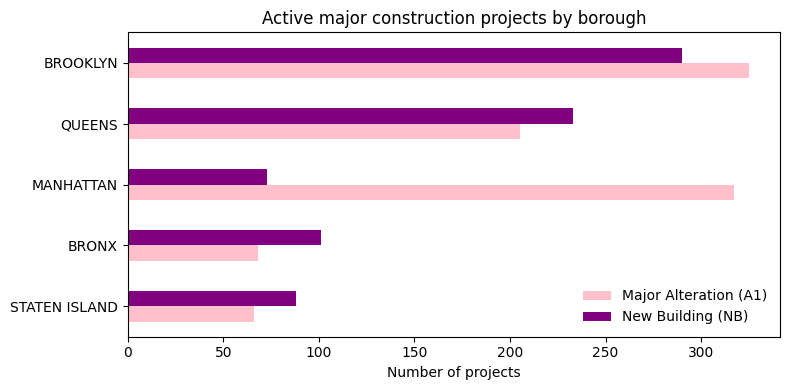

In [13]:
import matplotlib.pyplot as plt

# count projects for each borough and job type
chart_data = pd.crosstab(jobs["borough"], jobs["job_type"])
chart_data = chart_data.loc[chart_data.sum(axis=1).sort_values().index]
chart_data = chart_data.rename(columns={"NB": "New Building (NB)", "A1": "Major Alteration (A1)"})

ax = chart_data.plot(kind="barh", figsize=(8, 4), color={"New Building (NB)": "purple", "Major Alteration (A1)": "pink"})
ax.set_title("Active major construction projects by borough")
ax.set_xlabel("Number of projects")
ax.set_ylabel("")
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("projects_by_borough.svg")
plt.show()

# Key metrics graph 2:

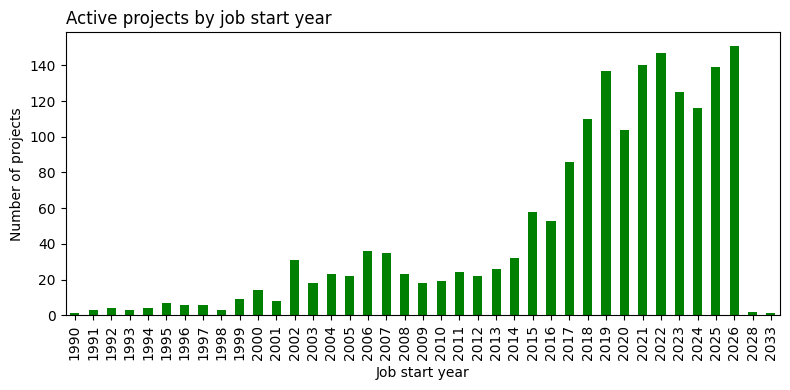

In [14]:
# getting the year from each start date and then count projects per year and sort by year
start_years = jobs["job_start"].dt.year.value_counts().sort_index()

ax = start_years.plot(kind="bar", figsize=(8, 4), color="green")
ax.set_title("Active projects by job start year", loc="left", fontsize=12)
ax.set_xlabel("Job start year")
ax.set_ylabel("Number of projects")

plt.tight_layout()
plt.show()

## Spatial join:

**tract_income:** ACS 2020–2024 median household income (table B19013), data.census.gov


**cb_2024_36_tract_500k.zip:**
2024 census tract boundaries for New York, data.gov

In [15]:
import geopandas as gpd

# skiprows to skip the second header row of the long label
income = pd.read_csv("tract_income.csv", skiprows=[1])

# GEOIDFQ uses the same id format as GEO_ID in the income file, so keeping only nyc tracts
tracts = gpd.read_file("cb_2024_36_tract_500k.zip")
tracts = tracts[tracts["GEOIDFQ"].isin(income["GEO_ID"])]

tracts = tracts.to_crs("EPSG:2263")

print("NYC tracts:", len(tracts))

NYC tracts: 2324


In [16]:
# convert income to numbers and values that can't convert will be blank
as_number = pd.to_numeric(income["B19013_001E"], errors="coerce")

# show the original text of the values that became blank
income.loc[as_number.isna(), "B19013_001E"].value_counts().reset_index()

,B19013_001E,count
0,-,128
1,"250,000+",13


In [17]:
income["median_income"] = income["B19013_001E"].replace("250,000+", "250000")
income["median_income"] = pd.to_numeric(income["median_income"], errors="coerce")

# adding each tract's income to the tract shapes by matching GEOID
tracts = tracts.merge(income[["GEO_ID", "median_income"]], left_on="GEOIDFQ", right_on="GEO_ID")

# split tracts into 3 equal groups by income
tracts["income_group"] = pd.qcut(tracts["median_income"], 3, labels=["Low", "Middle", "High"])

tracts.groupby("income_group", observed=True)["median_income"].agg(["min", "max"]).reset_index()

,income_group,min,max
0,Low,11094.0,69263.0
1,Middle,69276.0,98387.0
2,High,98438.0,250000.0


In [18]:
mapped = jobs.dropna(subset=["latitude"])

# building points from longitude/latitude and then convert to the tracts projection so they line up
project_points = gpd.points_from_xy(mapped["longitude"], mapped["latitude"])
jobs_gdf = gpd.GeoDataFrame(mapped, geometry=project_points, crs="EPSG:4326")
jobs_gdf = jobs_gdf.to_crs("EPSG:2263")

# attaching the income of the tract that each project is within
tract_info = tracts[["GEOID", "median_income", "income_group", "geometry"]]
jobs_gdf = gpd.sjoin(jobs_gdf, tract_info, how="left", predicate="within")
jobs_gdf = jobs_gdf.drop(columns="index_right") # helper column added by the join

print("Projects mapped:", len(jobs_gdf))
print("Projects without income data:", jobs_gdf["income_group"].isna().sum())

Projects mapped: 1757
Projects without income data: 45


## Summary table for joined data:

In [19]:
jobs_gdf["is_new_building"] = jobs_gdf["job_type"] == "NB"

income_summary = jobs_gdf.groupby("income_group", observed=True).agg(
    projects=("Job #", "count"),
    pct_new_building=("is_new_building", "mean"),
    pct_residential=("is_residential", "mean"),
).reset_index()

income_summary["pct_of_projects"] = income_summary["projects"] / income_summary["projects"].sum() * 100
income_summary["pct_new_building"] = income_summary["pct_new_building"] * 100
income_summary["pct_residential"] = income_summary["pct_residential"] * 100
income_summary = income_summary.round(1)
income_summary

,income_group,projects,pct_new_building,pct_residential,pct_of_projects
0,Low,453,52.5,63.8,26.5
1,Middle,493,50.1,67.3,28.8
2,High,766,36.0,68.7,44.7


## Spatial join map:

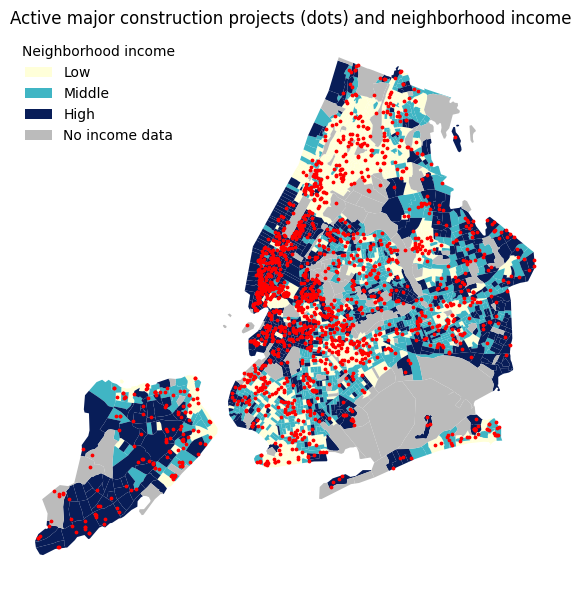

In [20]:
fig, ax = plt.subplots(figsize=(6, 6))
tracts.plot(ax=ax, column="income_group", cmap="YlGnBu", linewidth=0, legend= True,
            legend_kwds={"title": "Neighborhood income", "frameon": False, "loc": "upper left"},
            missing_kwds={"color": "#bbbbbb", "label": "No income data"})
jobs_gdf.plot(ax=ax, color="red", markersize=3)

ax.set_title("Active major construction projects (dots) and neighborhood income", loc="left", fontsize=12)
ax.set_axis_off()

plt.tight_layout()
plt.savefig("projects_income_map.svg")
plt.show()

## Exporting to excel:

In [21]:
# removing geometry column first since excel can't store map shapes
projects_table = jobs_gdf.drop(columns="geometry")

with pd.ExcelWriter("nyc_active_major_construction.xlsx") as writer:
    projects_table.to_excel(writer, sheet_name="projects", index=False)
    summary.to_excel(writer, sheet_name="summary_by_borough", index=False)
    income_summary.to_excel(writer, sheet_name="income_groups", index=False)

print("Saved nyc_active_major_construction.xlsx")

Saved nyc_active_major_construction.xlsx


## Conclusion:

I didn't have research questions off the bat so I started by looking at where active NB and A1 projects were by borough and job type. This then led me to wonder where in NYC is major construction concentrated and if there's a correlation between new development and the income level of the surrounding neighborhood.

I assumed there would be a lot of construction in Manhattan, especially near Midtown, because that's where I always see construction happening. I also wanted to look at areas that are gentrified or becoming gentrified, especially in Upper Manhattan and Brooklyn, to see whether they show more construction activity. For the data, I counted a permit as "active" if it was issued or re-issued and not yet expired, and I counted projects (Job #) instead of individual permits since one job can have several permits.

With more time, I would have liked to make a map showing active projects over the years, to better understand how construction has changed between neighborhoods and whether it follows gentrification.

The map that I did make shows big clusters in Midtown and Lower Manhattan, as well as in Harlem and in highly gentrified Brooklyn neighborhoods (Williamsburg, Bushwick, Bed Stuy). The high-income tracts have the most active projects overall but those projects are mostly likely alterations, and we do see from the first key metrics graph that an overwhelming majority of the construction in Manahttan is A1.

As a small note, for the second key metrics graph (active projects by job start year), it didn't seem right that a permit would be issued for a job starting in 2033, but it's in the data. I looked it up and found that in NYC, work on a permitted job generally has to start within 12 months, so I assumed the 2033 dates were typos.